# RollBack SMC: una run profonda, stime a ogni livello

Selezionare un runtime **GPU** in Colab e usare **Run all**. Il notebook è autonomo: codice e dipendenze sono nelle celle, senza import di file locali. Si conserva la notazione del LaTeX allegato. Una particella è sempre la traiettoria completa $\tau=(x_T,\ldots,x_0)$ sotto $P$, con $x_T=0$, $T=16$ e $Q_t(x_{t-1}\mid x_t)=\mathcal N(x_t,1/T)$. Per ciascuno dei due eventi $A=\{x_0\ge a\}$, $a=\Phi_{\rm normale}^{-1}(1-p_A)$ viene dal quantile **teorico** della normale standard, con $p_A\in\{10^{-4},10^{-5}\}$ esatto.

La **singola run principale** usa $N=128$, $R=20$, $\beta_k=0.25k$ e $\lambda=\beta_R=5$. Il kernel $M_k$ sceglie $d$ uniformemente in $\{1,\ldots,16\}$, conserva il prefisso, rigenera il suffisso con le transizioni di $P$ e applica MH con probabilità $1\wedge e^{\beta_k[\Phi(\tau')-\Phi(\tau)]}$. Si esegue una mutazione per livello. Dopo $G_k(\tau_{k-1})$, il resampling systematic avviene solo se ESS/N$<0.5$ **e** $k<R$, quindi mai dopo l'ultima pesatura. La ricorrenza di $\widehat Z_k$ usa il rapporto dei pesi normalizzati prima della mutazione a ogni livello, incluso quello senza resampling.

Dopo la mutazione di **ogni** livello calcoliamo separatamente, senza medie tra livelli,
$$\widehat p_{A,k}^{SMC}=\widehat Z_k\sum_n\overline W_k^{(n)}e^{-\beta_k\Phi(\tau_k^{(n)})}\mathbf1_A(\tau_k^{(n)}),$$
$$\widehat p_{A,k}^{SNIS}=\frac{\sum_n\overline W_k^{(n)}e^{-\beta_k\Phi(\tau_k^{(n)})}\mathbf1_A(\tau_k^{(n)})}{\sum_n\overline W_k^{(n)}e^{-\beta_k\Phi(\tau_k^{(n)})}}.$$
Il fattore inverso usa il **$\beta_k$ corrente**. Per confrontare il livello $k$ con una run che finirebbe lì, cloniamo la popolazione **dopo la pesatura e prima dell'eventuale resampling**, applichiamo $M_k$ sulla copia senza resampling finale e ne calcoliamo gli stessi stimatori. La run principale prosegue secondo la politica ESS; il costo delle copie è registrato separatamente e non incluso nel costo cumulativo principale.

Per ciascun livello sono registrati entrambe le stime, numero di particelle in $A$, ESS/N e massimo peso di $\overline W_k^{(n)}$, ESS/N e massimo peso dopo la correzione inversa su **tutte** le particelle, frazione di antenati iniziali distinti, tempo GPU e transizioni cumulative. Il tempo misura la stima completa con sincronizzazione CUDA prima e dopo ogni segmento; vengono riportati anche i normali generati dal codice GPU per il suffisso, che usa un buffer di lunghezza $T$ per particella.

Le repliche indipendenti dell'intera procedura stimano bias, varianza, RMSE e frequenza di zeri **a ciascun $\beta_k$ separatamente**. Il crude MC genera traiettorie complete da $P$ ed è confrontato con il costo cumulativo di ogni livello, sia in transizioni usate sia in tempo GPU. Per il confronto per transizioni riportiamo anche l'RMSE binomiale esatto $\sqrt{p_A(1-p_A)/n}$: per $10^{-5}$ un numero finito di repliche crude con pochi campioni può produrre molte stime nulle. Nessuna formula di varianza senza resampling è applicata alle run SMC con resampling.

In [1]:
import importlib.util, subprocess, sys
missing = [x for x in ['numpy','scipy','pandas','matplotlib','torch'] if importlib.util.find_spec(x) is None]
if missing: subprocess.check_call([sys.executable,'-m','pip','install','-q',*missing])
print('Dependencies ready; CUDA GPU required.')

Dependencies ready; CUDA GPU required.


In [2]:
"""One deep-tilt RollBack SMC run with per-level estimators and terminal copies."""
import math
import time
import numpy as np
import torch
from scipy.stats import norm

T = 16
N = 128
R = 20
DELTA_BETA = 0.25
LAMBDA = DELTA_BETA * R
P_EVENTS = (1e-4, 1e-5)
THRESHOLDS = tuple(float(norm.isf(p)) for p in P_EVENTS)
DEVICE = torch.device("cuda:0")
DTYPE = torch.float32


def require_gpu():
    if not torch.cuda.is_available():
        raise RuntimeError("Select a Colab GPU runtime; all estimators use CUDA.")
    torch.set_grad_enabled(False)
    return {"device": str(DEVICE), "gpu": torch.cuda.get_device_name(DEVICE),
            "torch": torch.__version__, "cuda_runtime": torch.version.cuda,
            "T": T, "N": N, "R": R, "lambda": LAMBDA,
            "p_A": list(P_EVENTS), "thresholds_theoretical": list(THRESHOLDS),
            "dtype": str(DTYPE)}


def make_seed(stream, rep, level=0, root=20261001):
    return int(np.random.SeedSequence([root, stream, rep, level]).generate_state(1, dtype=np.uint64)[0] % np.uint64(2**63-1))


def generator(seed):
    return torch.Generator(device=DEVICE).manual_seed(int(seed))


def gaussian_paths(count, rng):
    increments = torch.randn((count, T), device=DEVICE, dtype=DTYPE, generator=rng) / math.sqrt(T)
    return torch.cat((torch.zeros((count, 1), device=DEVICE, dtype=DTYPE), increments.cumsum(1)), dim=1)


def rollback_M_k(paths, beta, rng):
    count = paths.shape[0]
    d = torch.randint(1, T+1, (count,), device=DEVICE, generator=rng)
    cut = T-d
    column = torch.arange(T, device=DEVICE)[None, :]
    regenerate = column >= cut[:, None]
    # Padded CUDA draw: all T normals are drawn; only d are used per path.
    increments = torch.randn((count, T), device=DEVICE, dtype=DTYPE, generator=rng) / math.sqrt(T)
    increments = torch.where(regenerate, increments, 0.0)
    anchor = paths.gather(1, cut[:, None])
    future = anchor + increments.cumsum(1)
    proposal = torch.cat((paths[:, :1], torch.where(regenerate, future, paths[:, 1:])), dim=1)
    log_alpha = torch.minimum(torch.zeros((), device=DEVICE, dtype=DTYPE),
                              beta*(proposal[:, -1]-paths[:, -1]))
    accepted = torch.log(torch.rand(count, device=DEVICE, dtype=DTYPE, generator=rng)) < log_alpha
    return torch.where(accepted[:, None], proposal, paths), d, accepted


def systematic(log_weights, rng, offset=None):
    count = len(log_weights)
    cumulative = log_weights.exp().cumsum(0)
    cumulative[-1] = 1.0
    if offset is None:
        offset = torch.rand((), device=DEVICE, generator=rng)
    points = (torch.arange(count, device=DEVICE, dtype=DTYPE)+offset)/count
    return torch.searchsorted(cumulative, points, right=False)


def timed(function, *args):
    torch.cuda.synchronize(DEVICE)
    begin = time.perf_counter()
    value = function(*args)
    torch.cuda.synchronize(DEVICE)
    return value, time.perf_counter()-begin


@torch.inference_mode()
def initialize(seed, count=N):
    rng = generator(seed)
    return {"paths": gaussian_paths(count, rng),
            "log_weights": torch.full((count,), -math.log(count), device=DEVICE, dtype=DTYPE),
            "log_z": torch.zeros((), device=DEVICE, dtype=DTYPE),
            "roots": torch.arange(count, device=DEVICE), "rng": rng}


@torch.inference_mode()
def weight_before_M_k(state, beta):
    paths, log_weights = state["paths"], state["log_weights"]
    unnormalized = log_weights + DELTA_BETA*paths[:, -1]
    log_increment = torch.logsumexp(unnormalized, 0)
    state["log_z"] = state["log_z"]+log_increment
    state["log_weights"] = unnormalized-log_increment
    pre_ess = torch.exp(-torch.logsumexp(2*state["log_weights"], 0))/len(paths)
    pre_max = state["log_weights"].max().exp()
    return {"pre_ess_fraction": float(pre_ess.item()),
            "pre_max_weight": float(pre_max.item()),
            "log_increment": float(log_increment.item())}


@torch.inference_mode()
def evaluate_level(paths, log_weights, log_z, roots, beta):
    count = len(paths)
    terminal = paths[:, -1]
    corrected_log_weights = log_weights-beta*terminal
    log_denominator = torch.logsumexp(corrected_log_weights, 0)
    normalized_corrected = corrected_log_weights-log_denominator
    thresholds = torch.tensor(THRESHOLDS, device=DEVICE, dtype=DTYPE)
    event = terminal[:, None] >= thresholds[None, :]
    log_numerators = torch.logsumexp(
        torch.where(event, corrected_log_weights[:, None], -torch.inf), dim=0)
    smc_estimates = torch.exp(log_z+log_numerators)
    snis_estimates = torch.exp(log_numerators-log_denominator)
    forward_ess = torch.exp(-torch.logsumexp(2*log_weights, 0))/count
    reverse_ess = torch.exp(-torch.logsumexp(2*normalized_corrected, 0))/count
    distinct_roots = torch.unique(roots).numel()
    return {"smc": smc_estimates.cpu().tolist(),
            "snis": snis_estimates.cpu().tolist(),
            "event_particles": event.sum(0).cpu().tolist(),
            "smc_ess_fraction": float(forward_ess.item()),
            "smc_max_weight": float(log_weights.max().exp().item()),
            "reverse_ess_fraction": float(reverse_ess.item()),
            "reverse_max_weight": float(normalized_corrected.max().exp().item()),
            "distinct_root_fraction": float(distinct_roots/count),
            "z_hat": float(log_z.exp().item())}


@torch.inference_mode()
def terminal_copy_evaluation(state, beta, seed, debug=False):
    """Copy AFTER weighting, BEFORE resampling; mutate with NO terminal selection."""
    rng = generator(seed)
    paths = state["paths"].clone()
    weights = state["log_weights"].clone()
    roots = state["roots"].clone()
    paths, depths, _ = rollback_M_k(paths, beta, rng)
    result = evaluate_level(paths, weights, state["log_z"], roots, beta)
    result["extra_used_transitions"] = int(depths.sum().item())
    result["extra_gaussian_draws"] = len(paths)*T
    if debug:
        result.update(paths=paths, log_weights=weights, roots=roots,
                      log_z=state["log_z"].clone())
    return result


@torch.inference_mode()
def main_resample_mutate_evaluate(state, beta, level, pre_ess_fraction, debug=False):
    count = len(state["paths"])
    selected = level < R and pre_ess_fraction < .5
    if selected:
        parents = systematic(state["log_weights"], state["rng"])
        state["paths"] = state["paths"].index_select(0, parents)
        state["roots"] = state["roots"].index_select(0, parents)
        state["log_weights"] = torch.full_like(state["log_weights"], -math.log(count))
    state["paths"], depths, _ = rollback_M_k(state["paths"], beta, state["rng"])
    result = evaluate_level(state["paths"], state["log_weights"], state["log_z"],
                            state["roots"], beta)
    result["resampled"] = bool(selected)
    result["used_transitions_stage"] = int(depths.sum().item())
    result["gaussian_draws_stage"] = count*T
    if debug:
        result.update(paths=state["paths"].clone(),
                      log_weights=state["log_weights"].clone(),
                      roots=state["roots"].clone(), log_z=state["log_z"].clone())
    return result


def run_deep(seed, count=N, debug=False):
    """All 20 levels of ONE SMC run; no averaging of estimates across levels."""
    state, initial_seconds = timed(initialize, seed, count)
    main_seconds = initial_seconds
    extra_seconds = 0.0
    main_transitions = count*T
    extra_transitions = 0
    main_gaussian_draws = count*T
    extra_gaussian_draws = 0
    rows = []
    traces = []
    for level in range(1, R+1):
        beta = DELTA_BETA*level
        if debug:
            before = {"x": state["paths"][:, -1].clone(),
                      "log_weights": state["log_weights"].clone(),
                      "log_z": state["log_z"].clone(),
                      "roots": state["roots"].clone()}
        pre, elapsed = timed(weight_before_M_k, state, beta)
        main_seconds += elapsed
        terminal, elapsed = timed(terminal_copy_evaluation, state, beta,
                                  make_seed(2, seed, level), debug)
        terminal_elapsed = elapsed
        extra_seconds += terminal_elapsed
        extra_transitions += terminal["extra_used_transitions"]
        extra_gaussian_draws += terminal["extra_gaussian_draws"]
        main, elapsed = timed(main_resample_mutate_evaluate, state, beta, level,
                              pre["pre_ess_fraction"], debug)
        main_elapsed = elapsed
        main_seconds += elapsed
        main_transitions += main["used_transitions_stage"]
        main_gaussian_draws += main["gaussian_draws_stage"]
        common = {"level": level, "beta": beta, "seed": seed, "N": count,
                  "pre_ess_fraction": pre["pre_ess_fraction"],
                  "pre_max_weight": pre["pre_max_weight"],
                  "log_z_increment": pre["log_increment"],
                  "main_cumulative_seconds": main_seconds,
                  "main_cumulative_transitions": main_transitions,
                  "main_cumulative_gaussian_draws": main_gaussian_draws,
                  "terminal_copy_cumulative_seconds": main_seconds-main_elapsed+terminal_elapsed,
                  "terminal_copy_cumulative_transitions": main_transitions-main["used_transitions_stage"]+terminal["extra_used_transitions"],
                  "extra_cumulative_seconds": extra_seconds,
                  "extra_cumulative_transitions": extra_transitions,
                  "extra_cumulative_gaussian_draws": extra_gaussian_draws}
        for label, result in (("main", main), ("terminal_copy", terminal)):
            for index, p_true in enumerate(P_EVENTS):
                rows.append({**common, "population": label, "p_A": p_true,
                             "smc": result["smc"][index],
                             "snis": result["snis"][index],
                             "event_particles": result["event_particles"][index],
                             "smc_ess_fraction": result["smc_ess_fraction"],
                             "smc_max_weight": result["smc_max_weight"],
                             "reverse_ess_fraction": result["reverse_ess_fraction"],
                             "reverse_max_weight": result["reverse_max_weight"],
                             "distinct_root_fraction": result["distinct_root_fraction"],
                             "resampled": result.get("resampled", False),
                             "z_hat": result["z_hat"]})
        if debug:
            traces.append({"level": level, "beta": beta, "before": before,
                           "weighted_log_weights": state["log_weights"].clone() if not main["resampled"] else None,
                           "pre": pre, "main": main, "terminal": terminal})
    return rows, traces


@torch.inference_mode()
def crude_paths_two_events(count, seed, chunk_size=262144):
    rng = generator(seed)
    hits = torch.zeros(2, device=DEVICE, dtype=torch.int64)
    thresholds = torch.tensor(THRESHOLDS, device=DEVICE, dtype=DTYPE)
    for start in range(0, count, chunk_size):
        paths = gaussian_paths(min(chunk_size, count-start), rng)
        hits += (paths[:, -1, None] >= thresholds).sum(0)
    return (hits.to(torch.float64)/count).cpu().tolist()


@torch.inference_mode()
def crude_prefix_estimates(counts, seed, chunk_size=262144):
    """Use common P paths across level budgets, retaining correct marginal MC law."""
    rng = generator(seed)
    requested = np.asarray(counts, dtype=int)
    unique = np.unique(requested)
    maximum = int(unique[-1])
    thresholds = torch.tensor(THRESHOLDS, device=DEVICE, dtype=DTYPE)
    hits = torch.zeros(2, device=DEVICE, dtype=torch.int64)
    values = {}
    previous = 0
    for end in range(chunk_size, maximum+chunk_size, chunk_size):
        end = min(end, maximum)
        paths = gaussian_paths(end-previous, rng)
        event_cumulative = (paths[:, -1, None] >= thresholds).to(torch.int32).cumsum(0)
        for target in unique[(unique > previous) & (unique <= end)]:
            hit_at_target = hits+event_cumulative[int(target-previous-1)]
            values[int(target)] = (hit_at_target.to(torch.float64)/int(target)).cpu().tolist()
        hits += event_cumulative[-1].to(torch.int64)
        previous = end
        if end == maximum:
            break
    return [values[int(n)] for n in requested]


def warmup(repetitions=20):
    for rep in range(repetitions):
        seed = make_seed(99, rep)
        state = initialize(seed)
        pre = weight_before_M_k(state, .25)
        terminal_copy_evaluation(state, .25, make_seed(100, rep))
        main_resample_mutate_evaluate(state, .25, 1, pre["pre_ess_fraction"])
        crude_paths_two_events(32768, seed)
    torch.cuda.synchronize(DEVICE)


In [3]:
"""Tests, independent replications, crude-MC budgets and plots for deep tilt."""
from pathlib import Path
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy.stats import norm

OUT = Path("deep_tilt_results")
ROOT_SEED = 20261001
REPS = 320
CRUDE_REPS = 320
SINGLE_SEED = make_seed(1, 0, root=ROOT_SEED)


def check_algorithm():
    device = require_gpu()
    assert (T, N, R, DELTA_BETA, LAMBDA) == (16, 128, 20, .25, 5.0)
    for p, threshold in zip(P_EVENTS, THRESHOLDS):
        assert abs(threshold-norm.isf(p)) < 1e-14
    paths = gaussian_paths(131072, generator(make_seed(90, 0)))
    assert abs(paths[:, -1].mean().item()) < .012
    assert abs(paths[:, -1].var(unbiased=True).item()-1) < .018
    beta = 1.5
    tilted = paths + torch.arange(T+1, device=DEVICE, dtype=DTYPE)[None, :]*(beta/T)
    moved, depths, _ = rollback_M_k(tilted, beta, generator(make_seed(90, 1)))
    counts = torch.bincount(depths, minlength=T+1)[1:].cpu().numpy()
    assert counts.shape == (T,) and np.max(abs(counts-len(paths)/T))/(len(paths)/T) < .055
    cut = T-depths
    assert torch.all(torch.where(torch.arange(T+1, device=DEVICE)[None, :] <= cut[:, None],
                                 moved == tilted, True))
    assert abs(moved[:, -1].mean().item()-beta) < .025
    assert abs(moved[:, -1].var(unbiased=True).item()-1) < .025
    weights = np.array([.05, .35, .10, .50], dtype=np.float32)
    parents = systematic(torch.tensor(np.log(weights), device=DEVICE), generator(1),
                         torch.tensor(.37, device=DEVICE)).cpu().numpy()
    np.testing.assert_array_equal(parents, np.searchsorted(np.cumsum(weights), (np.arange(4)+.37)/4))

    rows, traces = run_deep(make_seed(91, 0), debug=True)
    assert len(rows) == R*len(P_EVENTS)*2 and len(traces) == R
    assert not any(row["resampled"] for row in rows if row["level"] == R)
    selected = [t["level"] for t in traces if t["main"]["resampled"]]
    assert selected, "The resampling branch must actually execute in tests."
    unselected = [t["level"] for t in traces if not t["main"]["resampled"]]
    assert unselected
    for trace in traces:
        level, beta = trace["level"], trace["beta"]
        before = trace["before"]
        unnorm = before["log_weights"]+DELTA_BETA*before["x"]
        increment = torch.logsumexp(unnorm, 0)
        pre_weights = unnorm-increment
        assert abs(increment.item()-trace["pre"]["log_increment"]) < 2e-6
        assert abs((before["log_z"]+increment-trace["terminal"]["log_z"]).item()) < 3e-6
        expected_ess = torch.exp(-torch.logsumexp(2*pre_weights, 0)).item()/N
        assert abs(expected_ess-trace["pre"]["pre_ess_fraction"]) < 2e-6
        assert trace["main"]["resampled"] == (level < R and expected_ess < .5)
        torch.testing.assert_close(trace["terminal"]["log_weights"], pre_weights)
        torch.testing.assert_close(trace["terminal"]["roots"], before["roots"])
        for result in (trace["main"], trace["terminal"]):
            x = result["paths"][:, -1].cpu().numpy().astype(float)
            w = result["log_weights"].exp().cpu().numpy().astype(float)
            z = math.exp(result["log_z"].item())
            reverse = w*np.exp(-beta*x)
            assert abs(result["reverse_ess_fraction"]-1/(N*np.sum((reverse/reverse.sum())**2))) < 2e-5
            for j, threshold in enumerate(THRESHOLDS):
                numerator = np.sum(reverse*(x >= threshold))
                assert abs(result["smc"][j]-z*numerator) < max(2e-8, 2e-4*P_EVENTS[j])
                assert abs(result["snis"][j]-numerator/reverse.sum()) < max(2e-8, 2e-4*P_EVENTS[j])
            assert result["event_particles"][1] <= result["event_particles"][0]
    return device | {"uniform_depth_min": int(counts.min()),
                     "uniform_depth_max": int(counts.max()),
                     "resampled_test_levels": selected,
                     "no_resampling_test_levels": unselected,
                     "no_final_resampling": True}


def summarize_estimates(frame):
    records = []
    keys = ["population", "p_A", "level", "beta"]
    for key, group in frame.groupby(keys, sort=True):
        p_true = key[1]
        for estimator in ("smc", "snis"):
            vals = group[estimator].to_numpy(dtype=float)
            errors = vals-p_true
            squared = errors*errors
            rmse = float(np.sqrt(squared.mean()))
            records.append(dict(zip(keys, key)) | {"estimator": estimator,
                           "runs": len(group), "bias": float(errors.mean()),
                           "variance": float(vals.var(ddof=1)), "rmse": rmse,
                           "rmse_se": float(squared.std(ddof=1)/(2*np.sqrt(len(group))*rmse)) if rmse > 0 else np.nan,
                           "zero_fraction": float(np.mean(vals == 0)),
                           "median_event_particles": float(group.event_particles.median()),
                           "mean_event_particles": float(group.event_particles.mean()),
                           "median_smc_ess_fraction": float(group.smc_ess_fraction.median()),
                           "median_reverse_ess_fraction": float(group.reverse_ess_fraction.median()),
                           "median_root_fraction": float(group.distinct_root_fraction.median()),
                           "median_main_cumulative_ms": float(group.main_cumulative_seconds.median()*1000),
                           "median_terminal_copy_cumulative_ms": float(group.terminal_copy_cumulative_seconds.median()*1000),
                           "median_main_transitions": float(group.main_cumulative_transitions.median()),
                           "median_terminal_copy_transitions": float(group.terminal_copy_cumulative_transitions.median())})
    return pd.DataFrame(records)


def diagnostic_quantiles(frame):
    records = []
    unique = frame[frame.p_A == P_EVENTS[0]]
    for (population, level, beta), group in unique.groupby(["population", "level", "beta"]):
        for metric in ("pre_ess_fraction", "pre_max_weight", "smc_ess_fraction",
                       "smc_max_weight", "reverse_ess_fraction", "reverse_max_weight",
                       "distinct_root_fraction", "event_particles",
                       "main_cumulative_seconds", "main_cumulative_transitions",
                       "extra_cumulative_seconds", "extra_cumulative_transitions"):
            value = group[metric]
            records.append({"population": population, "level": level, "beta": beta,
                            "metric": metric, "minimum": float(value.min()),
                            "p05": float(value.quantile(.05)), "p25": float(value.quantile(.25)),
                            "median": float(value.median()), "p75": float(value.quantile(.75)),
                            "p95": float(value.quantile(.95)), "maximum": float(value.max())})
    return pd.DataFrame(records)


def median_crude_latency(count, stream, level, reps=8):
    times = []
    # Discard short-lived clock/allocation transients before measuring this size.
    for rep in range(4):
        timed(crude_paths_two_events, int(count), make_seed(stream+1000, rep, level))
    for rep in range(reps):
        _, elapsed = timed(crude_paths_two_events, int(count), make_seed(stream, rep, level))
        times.append(elapsed)
    return float(np.median(times))


def calibrate_count(target, initial, level, stream):
    count = int(np.clip(round(initial/128)*128, 128, 12000000))
    for iteration in range(6):
        elapsed = median_crude_latency(count, stream+iteration, level, reps=24)
        ratio = np.clip(target/max(elapsed, 1e-9), .4, 2.5)
        updated = int(np.clip(round(count*ratio/128)*128, 128, 12000000))
        if abs(updated-count) <= 128:
            break
        count = updated
    measured = median_crude_latency(count, stream+20, level, reps=48)
    for correction in range(2):
        if abs(measured/target-1) <= .08:
            break
        ratio = np.clip(target/max(measured, 1e-9), .5, 2.0)
        count = int(np.clip(round(count*ratio/128)*128, 128, 12000000))
        measured = median_crude_latency(count, stream+30+correction, level, reps=48)
    return count, measured


def prepare_crude_budgets(frame):
    subset = frame[frame.p_A == P_EVENTS[0]]
    rows = []
    for population in ("main", "terminal_copy"):
        previous_count = 4096
        previous_target = None
        for level in range(1, R+1):
            group = subset[(subset.population == population) & (subset.level == level)]
            if population == "main":
                target_seconds = float(group.main_cumulative_seconds.median())
                target_transitions = float(group.main_cumulative_transitions.median())
            else:
                target_seconds = float(group.terminal_copy_cumulative_seconds.median())
                target_transitions = float(group.terminal_copy_cumulative_transitions.median())
            transitions_n = max(1, int(round(target_transitions/T)))
            if previous_target is not None:
                previous_count = max(128, int(previous_count*target_seconds/previous_target))
            time_n, measured_seconds = calibrate_count(target_seconds, previous_count, level,
                                                       300 if population == "main" else 400)
            previous_count, previous_target = time_n, target_seconds
            rows.append({"population": population, "level": level,
                         "beta": DELTA_BETA*level, "cost_match": "transitions",
                         "crude_n": transitions_n,
                         "target_smc_transitions": target_transitions,
                         "target_smc_seconds": target_seconds,
                         "calibrated_crude_seconds": median_crude_latency(transitions_n, 500, level, reps=24)})
            rows.append({"population": population, "level": level,
                         "beta": DELTA_BETA*level, "cost_match": "gpu_time",
                         "crude_n": time_n,
                         "target_smc_transitions": target_transitions,
                         "target_smc_seconds": target_seconds,
                         "calibrated_crude_seconds": measured_seconds})
    return pd.DataFrame(rows)


def run_crude_budgets(budgets):
    requested = budgets.crude_n.to_numpy(dtype=int)
    rows = []
    for rep in range(CRUDE_REPS):
        seed = make_seed(50, rep)
        estimates = crude_prefix_estimates(requested, seed)
        for budget, values in zip(budgets.to_dict("records"), estimates):
            for event_index, p_true in enumerate(P_EVENTS):
                rows.append({"run": rep, "seed": seed, "population": budget["population"],
                             "level": budget["level"], "beta": budget["beta"],
                             "cost_match": budget["cost_match"], "p_A": p_true,
                             "crude_n": budget["crude_n"], "estimate": values[event_index]})
        if (rep+1) % 80 == 0:
            print(f"Crude MC independent replicates: {rep+1}/{CRUDE_REPS}", flush=True)
    return pd.DataFrame(rows)


def summarize_crude(frame, budgets):
    records = []
    keys = ["population", "cost_match", "p_A", "level", "beta", "crude_n"]
    for key, group in frame.groupby(keys, sort=True):
        p_true, count = key[2], key[5]
        errors = group.estimate.to_numpy()-p_true
        squared = errors*errors
        rmse = float(np.sqrt(squared.mean()))
        budget = budgets[(budgets.population == key[0]) & (budgets.cost_match == key[1]) &
                         (budgets.level == key[3])].iloc[0]
        records.append(dict(zip(keys, key)) | {"runs": len(group),
                       "bias": float(errors.mean()), "variance": float(group.estimate.var(ddof=1)),
                       "rmse": rmse,
                       "rmse_se": float(squared.std(ddof=1)/(2*np.sqrt(len(group))*rmse)) if rmse > 0 else np.nan,
                       "zero_fraction": float(np.mean(group.estimate == 0)),
                       "exact_binomial_rmse": float(np.sqrt(p_true*(1-p_true)/count)),
                       "crude_transitions": count*T,
                       "calibrated_crude_ms": budget.calibrated_crude_seconds*1000,
                       "target_smc_ms": budget.target_smc_seconds*1000,
                       "time_ratio_crude_to_smc": budget.calibrated_crude_seconds/budget.target_smc_seconds})
    return pd.DataFrame(records)


def plot_single_run(frame, out):
    fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
    for row_index, p_true in enumerate(P_EVENTS):
        for population, color in (("main", "#1e6da8"), ("terminal_copy", "#dd733d")):
            group = frame[(frame.p_A == p_true) & (frame.population == population)]
            for estimator, style in (("smc", "-"), ("snis", "--")):
                axes[row_index, 0].plot(group.beta, group[estimator], color=color, linestyle=style,
                                        marker=".", label=f"{population}, {estimator}")
            axes[row_index, 1].plot(group.beta, group.event_particles, marker="o", color=color,
                                    label=population)
        axes[row_index, 0].axhline(p_true, color="black", linestyle=":", label="exact $p_A$")
        axes[row_index, 0].set_yscale("symlog", linthresh=p_true/10)
        axes[row_index, 0].set_ylabel(f"estimate of $p_A={p_true:g}$")
        axes[row_index, 1].set_ylabel("particles terminating in A")
        for ax in axes[row_index]:
            ax.set_xlabel(r"current $\beta_k$")
            ax.grid(alpha=.2)
            ax.legend(fontsize=8)
    axes[0, 0].set_title("Per-level estimates; no averaging across levels")
    axes[0, 1].set_title("Rare-event particles")
    fig.savefig(out / "single_run.png", dpi=170)
    plt.close(fig)


def plot_replications(summary, crude, out):
    fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
    for i, p_true in enumerate(P_EVENTS):
        for j, population in enumerate(("main", "terminal_copy")):
            ax = axes[i, j]
            for estimator, style in (("smc", "-"), ("snis", "--")):
                sub = summary[(summary.p_A == p_true) & (summary.population == population) &
                              (summary.estimator == estimator)].sort_values("beta")
                ax.plot(sub.beta, sub.rmse, linestyle=style, marker="o", label=estimator)
                ax.fill_between(sub.beta, np.maximum(1e-12, sub.rmse-1.96*sub.rmse_se),
                                sub.rmse+1.96*sub.rmse_se, alpha=.12)
            for cost, color in (("transitions", "#555555"), ("gpu_time", "#cf7432")):
                sub = crude[(crude.p_A == p_true) & (crude.population == population) &
                            (crude.cost_match == cost)].sort_values("beta")
                ax.plot(sub.beta, sub.exact_binomial_rmse, marker="s", color=color,
                        label=f"crude MC, matched {cost} (exact binomial RMSE)")
            ax.set_yscale("log")
            ax.set_title(f"{population}, $p_A={p_true:g}$")
            ax.set_xlabel(r"current $\beta_k$")
            ax.set_ylabel("RMSE")
            ax.grid(alpha=.2)
            ax.legend(fontsize=7)
    fig.savefig(out / "rmse_by_level.png", dpi=170)
    plt.close(fig)


def plot_diagnostics(frame, out):
    data = frame[(frame.p_A == P_EVENTS[0]) & (frame.population == "main")]
    fig, axes = plt.subplots(2, 2, figsize=(11, 8), constrained_layout=True)
    for ax, metric, title in ((axes[0, 0], "smc_ess_fraction", "SMC ESS/N"),
                              (axes[0, 1], "reverse_ess_fraction", "Inverse-corrected ESS/N"),
                              (axes[1, 0], "distinct_root_fraction", "Distinct initial ancestor fraction"),
                              (axes[1, 1], "reverse_max_weight", "Largest corrected weight")):
        q = data.groupby("beta")[metric].quantile([.05, .25, .5, .75, .95]).unstack()
        x = q.index.to_numpy()
        ax.fill_between(x, q[.05], q[.95], alpha=.15)
        ax.fill_between(x, q[.25], q[.75], alpha=.3)
        ax.plot(x, q[.5], marker=".")
        ax.set_title(title + " (5–95%, 25–75%, median)")
        ax.set_xlabel(r"current $\beta_k$")
        ax.grid(alpha=.2)
    fig.savefig(out / "diagnostics_by_level.png", dpi=170)
    plt.close(fig)


def single_experiment():
    OUT.mkdir(exist_ok=True)
    single_rows, _ = run_deep(SINGLE_SEED)
    single = pd.DataFrame(single_rows)
    single.to_csv(OUT / "single_run.csv", index=False)
    plot_single_run(single, OUT)
    print("Single run first: seed", SINGLE_SEED, flush=True)
    print(single[(single.population == "main") & (single.p_A == P_EVENTS[1])][
        ["level", "beta", "smc", "snis", "event_particles", "smc_ess_fraction",
         "reverse_ess_fraction", "distinct_root_fraction", "main_cumulative_seconds",
         "main_cumulative_transitions"]].to_string(index=False), flush=True)
    return single


def replicated_experiment(checks):
    OUT.mkdir(exist_ok=True)
    all_rows = []
    for rep in range(REPS):
        rows, _ = run_deep(make_seed(10, rep))
        for row in rows:
            row["run"] = rep
        all_rows += rows
        if (rep+1) % 80 == 0:
            print(f"Independent full SMC runs: {rep+1}/{REPS}", flush=True)
    frame = pd.DataFrame(all_rows)
    frame.to_csv(OUT / "runs.csv", index=False)
    summary = summarize_estimates(frame)
    summary.to_csv(OUT / "summary.csv", index=False)
    diagnostics = diagnostic_quantiles(frame)
    diagnostics.to_csv(OUT / "diagnostic_quantiles.csv", index=False)
    plot_diagnostics(frame, OUT)
    budgets = prepare_crude_budgets(frame)
    budgets.to_csv(OUT / "crude_budgets.csv", index=False)
    crude_runs = run_crude_budgets(budgets)
    crude_runs.to_csv(OUT / "crude_runs.csv", index=False)
    crude_summary = summarize_crude(crude_runs, budgets)
    crude_summary.to_csv(OUT / "crude_summary.csv", index=False)
    plot_replications(summary, crude_summary, OUT)
    parameters = checks | {"root_seed": ROOT_SEED, "single_seed": SINGLE_SEED,
                           "independent_smc_runs": REPS, "independent_crude_runs": CRUDE_REPS,
                           "schedule": "beta_k=0.25*k, k=0,...,20",
                           "resampling": "systematic when ESS/N<0.5 and k<R",
                           "mutation": "one RollBack-MH per level, depth uniform 1,...,16",
                           "timing": "CUDA synchronize before and after each timed segment; main cumulative excludes terminal-copy evaluation",
                           "crude_time_matching": "standalone full-trajectory P sampler calibrated against median cumulative GPU time",
                           "crude_transition_matching": "median used Gaussian transitions divided by T=16",
                           "crude_estimates": "independent P trajectory pools by replicate; prefixes reused across level budgets"}
    (OUT / "parameters.json").write_text(json.dumps(parameters, indent=2), encoding="utf-8")
    print("\nMAIN SUMMARY (selected levels)\n", summary[(summary.population == "main") &
        (summary.level.isin([1, 5, 10, 15, 20]))].to_string(index=False), flush=True)
    print("\nCRUDE BUDGETS (selected levels)\n", budgets[budgets.level.isin([1, 5, 10, 15, 20])].to_string(index=False), flush=True)
    return summary, crude_summary, diagnostics, budgets


def main():
    OUT.mkdir(exist_ok=True)
    checks = check_algorithm()
    (OUT / "checks.json").write_text(json.dumps(checks, indent=2), encoding="utf-8")
    warmup(20)
    single = single_experiment()
    summary, crude_summary, diagnostics, budgets = replicated_experiment(checks)
    return single, summary, crude_summary, diagnostics, budgets




In [4]:
from IPython.display import display, Image
OUT.mkdir(exist_ok=True)
checks = check_algorithm()
(OUT/'checks.json').write_text(json.dumps(checks,indent=2),encoding='utf-8')
print('Tests passed:', checks)
warmup(20)

Tests passed: {'device': 'cuda:0', 'gpu': 'NVIDIA GeForce MX570 A', 'torch': '2.13.0+cu130', 'cuda_runtime': '13.0', 'T': 16, 'N': 128, 'R': 20, 'lambda': 5.0, 'p_A': [0.0001, 1e-05], 'thresholds_theoretical': [3.7190164854556804, 4.264890793922825], 'dtype': 'torch.float32', 'uniform_depth_min': 7955, 'uniform_depth_max': 8401, 'resampled_test_levels': [4, 9, 15], 'no_resampling_test_levels': [1, 2, 3, 5, 6, 7, 8, 10, 11, 12, 13, 14, 16, 17, 18, 19, 20], 'no_final_resampling': True}


## Prima: una sola run completa

Ogni riga è un livello della **medesima** run. Le tabelle della copia terminale mostrano cosa si otterrebbe fermandosi a quel livello senza resampling finale; le copie non alimentano i livelli successivi della run principale.

Single run first: seed 5057951913583579369


 level  beta  smc  snis  event_particles  smc_ess_fraction  reverse_ess_fraction  distinct_root_fraction  main_cumulative_seconds  main_cumulative_transitions
     1  0.25  0.0   0.0                0          0.937823              0.958913                1.000000                 0.002093                         3060
     2  0.50  0.0   0.0                0          0.793134              0.864368                1.000000                 0.003786                         4133
     3  0.75  0.0   0.0                0          0.564679              0.176678                1.000000                 0.005496                         5126
     4  1.00  0.0   0.0                0          1.000000              0.432326                0.671875                 0.008738                         6253
     5  1.25  0.0   0.0                0          0.928198              0.322778                0.671875                 0.013491                         7318
     6  1.50  0.0   0.0                0      

p_A=0.0001, main:


,level,beta,smc,snis,event_particles,smc_ess_fraction,smc_max_weight,reverse_ess_fraction,reverse_max_weight,distinct_root_fraction,main_cumulative_seconds,main_cumulative_transitions,terminal_copy_cumulative_seconds,terminal_copy_cumulative_transitions,extra_cumulative_seconds,extra_cumulative_transitions
0,1,0.25,0.000000,0.000000,0,0.937823,0.017519,0.958913,0.014765,1.000000,0.002093,3060,0.002753,3153,0.001751,1105
1,2,0.50,0.000000,0.000000,0,0.793134,0.034013,0.864368,0.022570,1.000000,0.003786,4133,0.003763,4118,0.003129,2163
2,3,0.75,0.000000,0.000000,0,0.564679,0.061728,0.176678,0.191323,1.000000,0.005496,5126,0.005554,5172,0.004562,3202
3,4,1.00,0.000000,0.000000,0,1.000000,0.007812,0.432326,0.055416,0.671875,0.008738,6253,0.007269,6267,0.005972,4343
4,5,1.25,0.000000,0.000000,0,0.928198,0.014161,0.322778,0.098198,0.671875,0.013491,7318,0.013626,7434,0.009551,5524
5,6,1.50,0.000000,0.000000,0,0.775523,0.023989,0.200865,0.162100,0.671875,0.016671,8471,0.018253,8335,0.013277,6541
6,7,1.75,0.000000,0.000000,0,0.602039,0.038001,0.295194,0.104992,0.671875,0.020928,9456,0.021315,9513,0.017084,7583
7,8,2.00,0.000000,0.000000,0,1.000000,0.007812,0.032193,0.478156,0.359375,0.025517,10588,0.025428,10382,0.020609,8509
8,9,2.25,0.000000,0.000000,0,0.958287,0.011013,0.160284,0.119351,0.359375,0.030039,11660,0.030564,11720,0.024517,9641
9,10,2.50,0.000000,0.000000,0,0.863517,0.014874,0.158707,0.111526,0.359375,0.036082,12738,0.034821,12773,0.028306,10754


p_A=0.0001, terminal_copy:


,level,beta,smc,snis,event_particles,smc_ess_fraction,smc_max_weight,reverse_ess_fraction,reverse_max_weight,distinct_root_fraction,main_cumulative_seconds,main_cumulative_transitions,terminal_copy_cumulative_seconds,terminal_copy_cumulative_transitions,extra_cumulative_seconds,extra_cumulative_transitions
0,1,0.25,0.000000,0.000000,0,0.937823,0.017519,0.959726,0.014606,1.000000,0.002093,3060,0.002753,3153,0.001751,1105
1,2,0.50,0.000000,0.000000,0,0.793134,0.034013,0.857446,0.020991,1.000000,0.003786,4133,0.003763,4118,0.003129,2163
2,3,0.75,0.000000,0.000000,0,0.564679,0.061728,0.712804,0.036961,1.000000,0.005496,5126,0.005554,5172,0.004562,3202
3,4,1.00,0.000000,0.000000,0,0.348594,0.103564,0.574615,0.038039,1.000000,0.008738,6253,0.007269,6267,0.005972,4343
4,5,1.25,0.000000,0.000000,0,0.928198,0.014161,0.343344,0.095236,0.671875,0.013491,7318,0.013626,7434,0.009551,5524
5,6,1.50,0.000000,0.000000,0,0.775523,0.023989,0.274242,0.085622,0.671875,0.016671,8471,0.018253,8335,0.013277,6541
6,7,1.75,0.000000,0.000000,0,0.602039,0.038001,0.255073,0.103282,0.671875,0.020928,9456,0.021315,9513,0.017084,7583
7,8,2.00,0.000280,0.000261,1,0.449537,0.057281,0.087207,0.276419,0.671875,0.025517,10588,0.025428,10382,0.020609,8509
8,9,2.25,0.000000,0.000000,0,0.958287,0.011013,0.038925,0.431946,0.359375,0.030039,11660,0.030564,11720,0.024517,9641
9,10,2.50,0.000000,0.000000,0,0.863517,0.014874,0.108604,0.216121,0.359375,0.036082,12738,0.034821,12773,0.028306,10754


p_A=1e-05, main:


,level,beta,smc,snis,event_particles,smc_ess_fraction,smc_max_weight,reverse_ess_fraction,reverse_max_weight,distinct_root_fraction,main_cumulative_seconds,main_cumulative_transitions,terminal_copy_cumulative_seconds,terminal_copy_cumulative_transitions,extra_cumulative_seconds,extra_cumulative_transitions
0,1,0.25,0.0,0.0,0,0.937823,0.017519,0.958913,0.014765,1.000000,0.002093,3060,0.002753,3153,0.001751,1105
1,2,0.50,0.0,0.0,0,0.793134,0.034013,0.864368,0.022570,1.000000,0.003786,4133,0.003763,4118,0.003129,2163
2,3,0.75,0.0,0.0,0,0.564679,0.061728,0.176678,0.191323,1.000000,0.005496,5126,0.005554,5172,0.004562,3202
3,4,1.00,0.0,0.0,0,1.000000,0.007812,0.432326,0.055416,0.671875,0.008738,6253,0.007269,6267,0.005972,4343
4,5,1.25,0.0,0.0,0,0.928198,0.014161,0.322778,0.098198,0.671875,0.013491,7318,0.013626,7434,0.009551,5524
5,6,1.50,0.0,0.0,0,0.775523,0.023989,0.200865,0.162100,0.671875,0.016671,8471,0.018253,8335,0.013277,6541
6,7,1.75,0.0,0.0,0,0.602039,0.038001,0.295194,0.104992,0.671875,0.020928,9456,0.021315,9513,0.017084,7583
7,8,2.00,0.0,0.0,0,1.000000,0.007812,0.032193,0.478156,0.359375,0.025517,10588,0.025428,10382,0.020609,8509
8,9,2.25,0.0,0.0,0,0.958287,0.011013,0.160284,0.119351,0.359375,0.030039,11660,0.030564,11720,0.024517,9641
9,10,2.50,0.0,0.0,0,0.863517,0.014874,0.158707,0.111526,0.359375,0.036082,12738,0.034821,12773,0.028306,10754


p_A=1e-05, terminal_copy:


,level,beta,smc,snis,event_particles,smc_ess_fraction,smc_max_weight,reverse_ess_fraction,reverse_max_weight,distinct_root_fraction,main_cumulative_seconds,main_cumulative_transitions,terminal_copy_cumulative_seconds,terminal_copy_cumulative_transitions,extra_cumulative_seconds,extra_cumulative_transitions
0,1,0.25,0.0,0.0,0,0.937823,0.017519,0.959726,0.014606,1.000000,0.002093,3060,0.002753,3153,0.001751,1105
1,2,0.50,0.0,0.0,0,0.793134,0.034013,0.857446,0.020991,1.000000,0.003786,4133,0.003763,4118,0.003129,2163
2,3,0.75,0.0,0.0,0,0.564679,0.061728,0.712804,0.036961,1.000000,0.005496,5126,0.005554,5172,0.004562,3202
3,4,1.00,0.0,0.0,0,0.348594,0.103564,0.574615,0.038039,1.000000,0.008738,6253,0.007269,6267,0.005972,4343
4,5,1.25,0.0,0.0,0,0.928198,0.014161,0.343344,0.095236,0.671875,0.013491,7318,0.013626,7434,0.009551,5524
5,6,1.50,0.0,0.0,0,0.775523,0.023989,0.274242,0.085622,0.671875,0.016671,8471,0.018253,8335,0.013277,6541
6,7,1.75,0.0,0.0,0,0.602039,0.038001,0.255073,0.103282,0.671875,0.020928,9456,0.021315,9513,0.017084,7583
7,8,2.00,0.0,0.0,0,0.449537,0.057281,0.087207,0.276419,0.671875,0.025517,10588,0.025428,10382,0.020609,8509
8,9,2.25,0.0,0.0,0,0.958287,0.011013,0.038925,0.431946,0.359375,0.030039,11660,0.030564,11720,0.024517,9641
9,10,2.50,0.0,0.0,0,0.863517,0.014874,0.108604,0.216121,0.359375,0.036082,12738,0.034821,12773,0.028306,10754


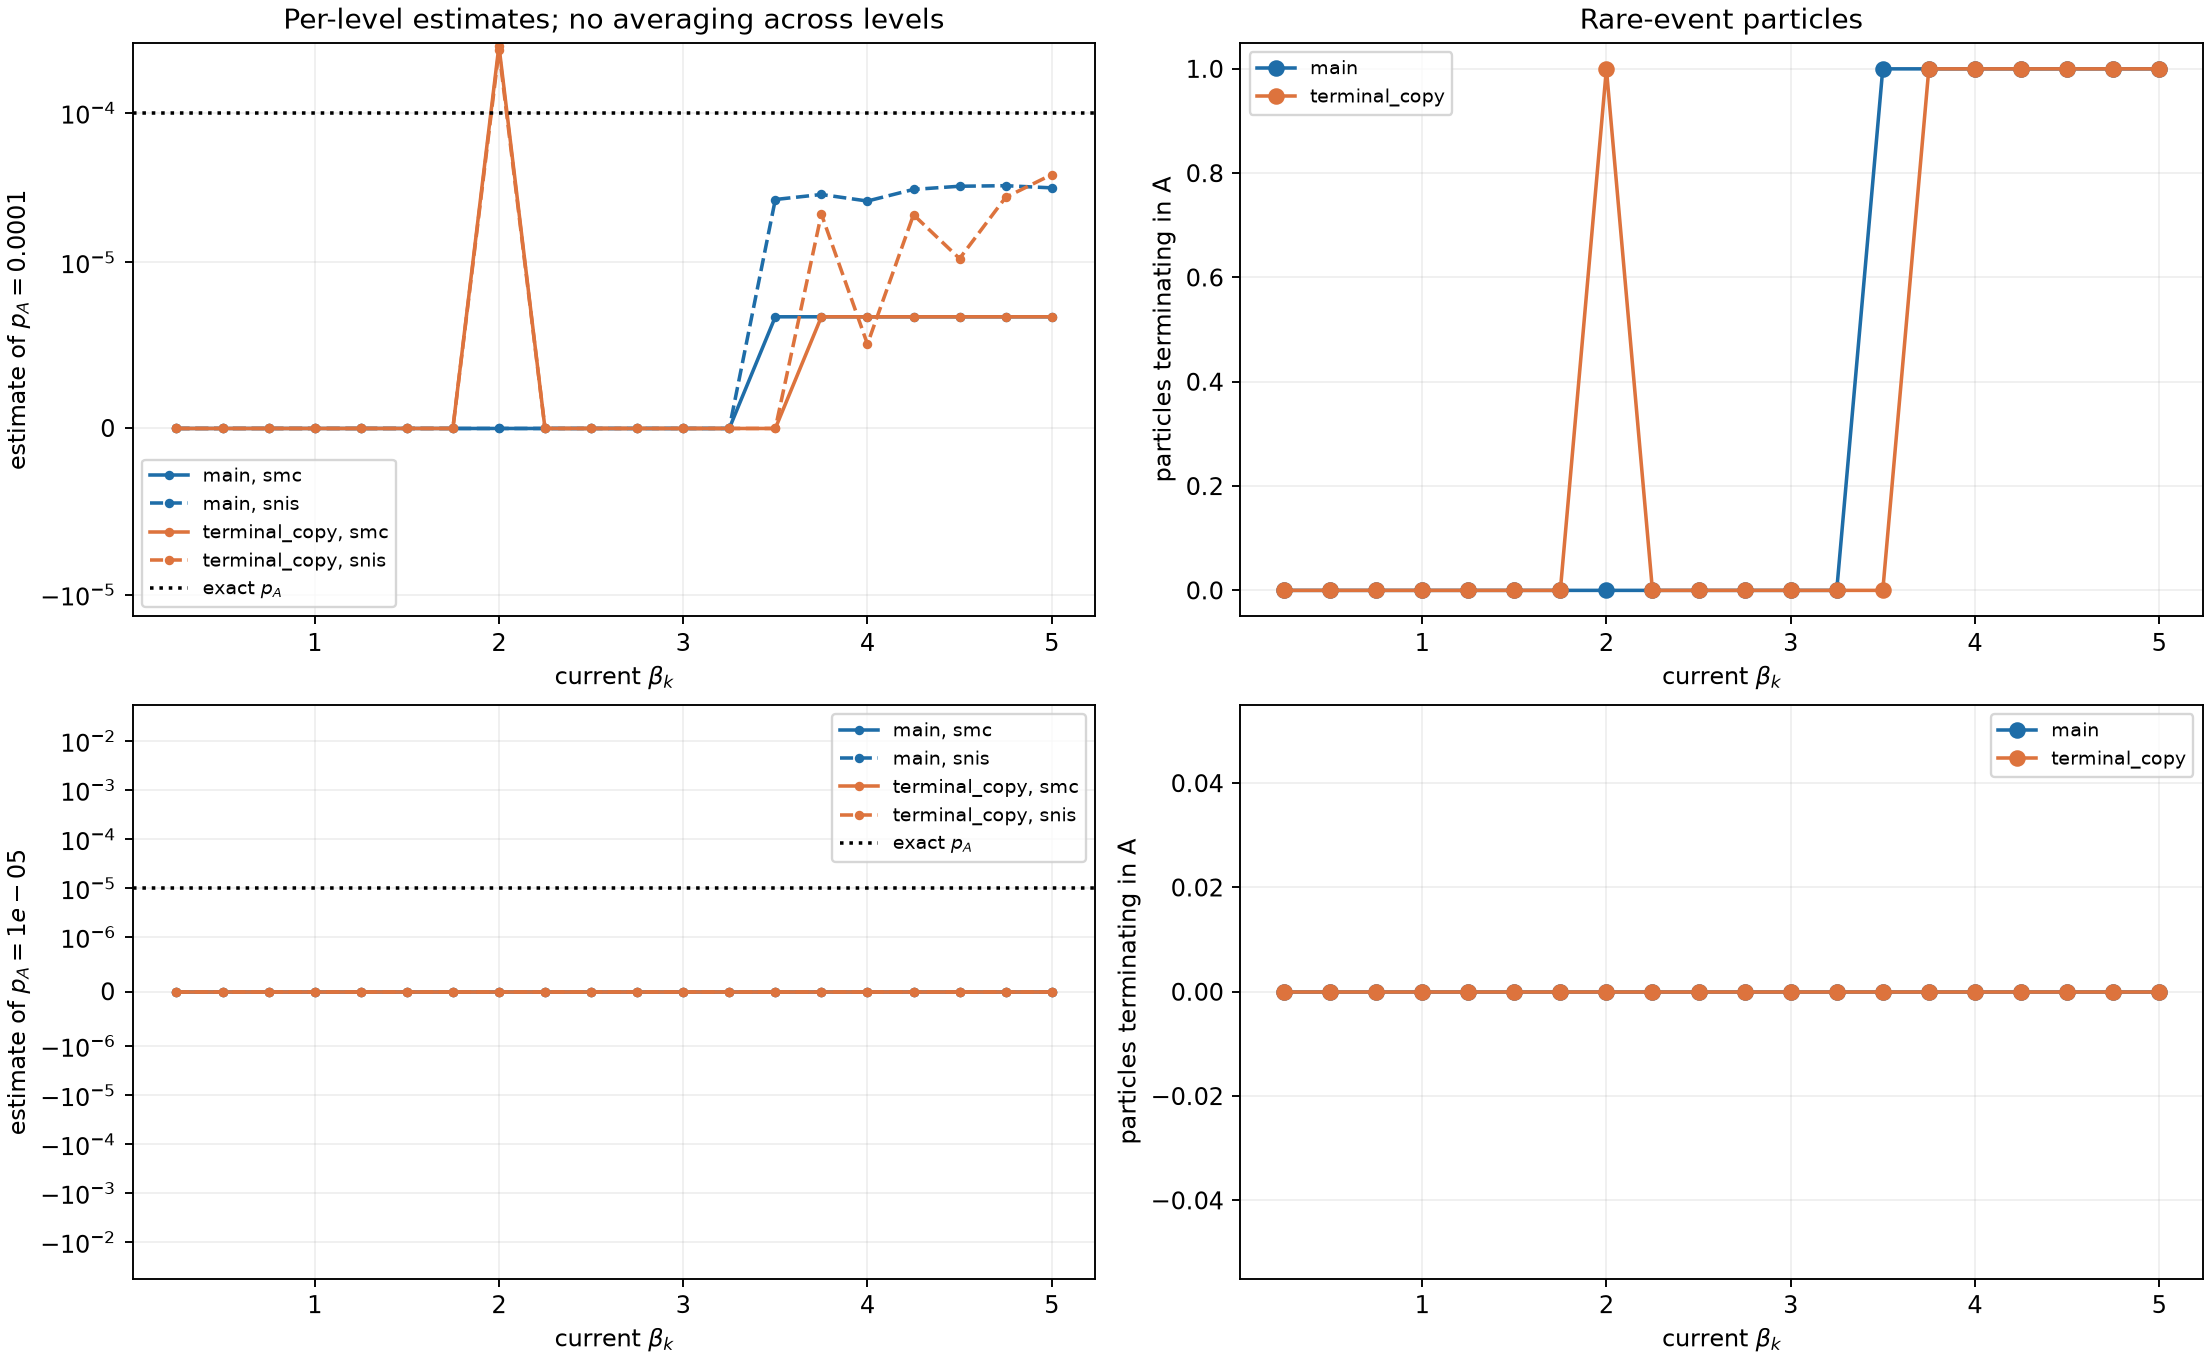

In [5]:
single = single_experiment()
pd.set_option('display.max_rows', 200)
columns = ['level','beta','smc','snis','event_particles','smc_ess_fraction','smc_max_weight','reverse_ess_fraction','reverse_max_weight','distinct_root_fraction','main_cumulative_seconds','main_cumulative_transitions','terminal_copy_cumulative_seconds','terminal_copy_cumulative_transitions','extra_cumulative_seconds','extra_cumulative_transitions']
for probability in P_EVENTS:
    for population in ('main','terminal_copy'):
        print(f'p_A={probability:g}, {population}:')
        display(single[(single.p_A==probability)&(single.population==population)][columns].reset_index(drop=True))
display(Image(filename=str(OUT/'single_run.png')))

## Poi: repliche indipendenti e crude MC

Ogni riga di `summary.csv` si riferisce a uno specifico $eta_k$, evento, popolazione e stimatore. Le stime **non** vengono mediate fra livelli. `runs.csv` conserva i seed e tutte le osservazioni delle run. `crude_budgets.csv` esplicita i campioni crude assegnati a ogni livello e mostra quanto tempo GPU abbiano effettivamente impiegato nella calibrazione.

Independent full SMC runs: 80/320


Independent full SMC runs: 160/320


Independent full SMC runs: 240/320


Independent full SMC runs: 320/320


Crude MC independent replicates: 80/320


Crude MC independent replicates: 160/320


... (6 outputs left out)

Per-level crude MC summary:


,population,cost_match,p_A,level,beta,crude_n,runs,bias,variance,rmse,rmse_se,zero_fraction,exact_binomial_rmse,crude_transitions,calibrated_crude_ms,target_smc_ms,time_ratio_crude_to_smc
0,main,gpu_time,0.00001,1,0.25,49920,320,-1.091747e-07,2.037707e-10,0.000014,8.354457e-07,0.612500,0.000014,798720,3.84545,3.98120,0.965902
1,main,gpu_time,0.00001,2,0.50,103936,320,-1.789563e-08,9.679173e-11,0.000010,4.606898e-07,0.356250,0.000010,1662976,7.98685,7.92055,1.008371
2,main,gpu_time,0.00001,3,0.75,152832,320,3.872226e-07,6.301770e-11,0.000008,3.446955e-07,0.190625,0.000008,2445312,11.68965,11.55540,1.011618
3,main,gpu_time,0.00001,4,1.00,201216,320,2.812401e-07,4.928039e-11,0.000007,3.961200e-07,0.128125,0.000007,3219456,15.29350,15.26230,1.002044
4,main,gpu_time,0.00001,5,1.25,251392,320,2.802595e-07,3.976767e-11,0.000006,3.347454e-07,0.068750,0.000006,4022272,19.15495,19.10335,1.002701
5,main,gpu_time,0.00001,6,1.50,295296,320,4.288917e-08,3.367119e-11,0.000006,2.624039e-07,0.053125,0.000006,4724736,22.57605,22.43450,1.006309
6,main,gpu_time,0.00001,7,1.75,345472,320,3.156551e-08,2.835667e-11,0.000005,2.275771e-07,0.043750,0.000005,5527552,26.31735,26.21360,1.003958
7,main,gpu_time,0.00001,8,2.00,365568,320,6.139761e-08,2.612754e-11,0.000005,2.150999e-07,0.037500,0.000005,5849088,29.64535,29.60665,1.001307
8,main,gpu_time,0.00001,9,2.25,413824,320,-5.464884e-08,2.340745e-11,0.000005,1.936529e-07,0.025000,0.000005,6621184,33.57105,33.51825,1.001575
9,main,gpu_time,0.00001,10,2.50,460288,320,-1.148846e-07,2.176816e-11,0.000005,1.924047e-07,0.015625,0.000005,7364608,37.43865,37.34740,1.002443


Transition and GPU-time budgets:


,population,level,beta,cost_match,crude_n,target_smc_transitions,target_smc_seconds,calibrated_crude_seconds
0,main,1,0.25,transitions,196,3133.0,0.003981,0.000264
1,main,1,0.25,gpu_time,49920,3133.0,0.003981,0.003845
2,main,2,0.50,transitions,264,4218.0,0.007921,0.000631
3,main,2,0.50,gpu_time,103936,4218.0,0.007921,0.007987
4,main,3,0.75,transitions,332,5308.0,0.011555,0.000378
5,main,3,0.75,gpu_time,152832,5308.0,0.011555,0.011690
6,main,4,1.00,transitions,400,6393.5,0.015262,0.000278
7,main,4,1.00,gpu_time,201216,6393.5,0.015262,0.015294
8,main,5,1.25,transitions,467,7478.0,0.019103,0.000292
9,main,5,1.25,gpu_time,251392,7478.0,0.019103,0.019155


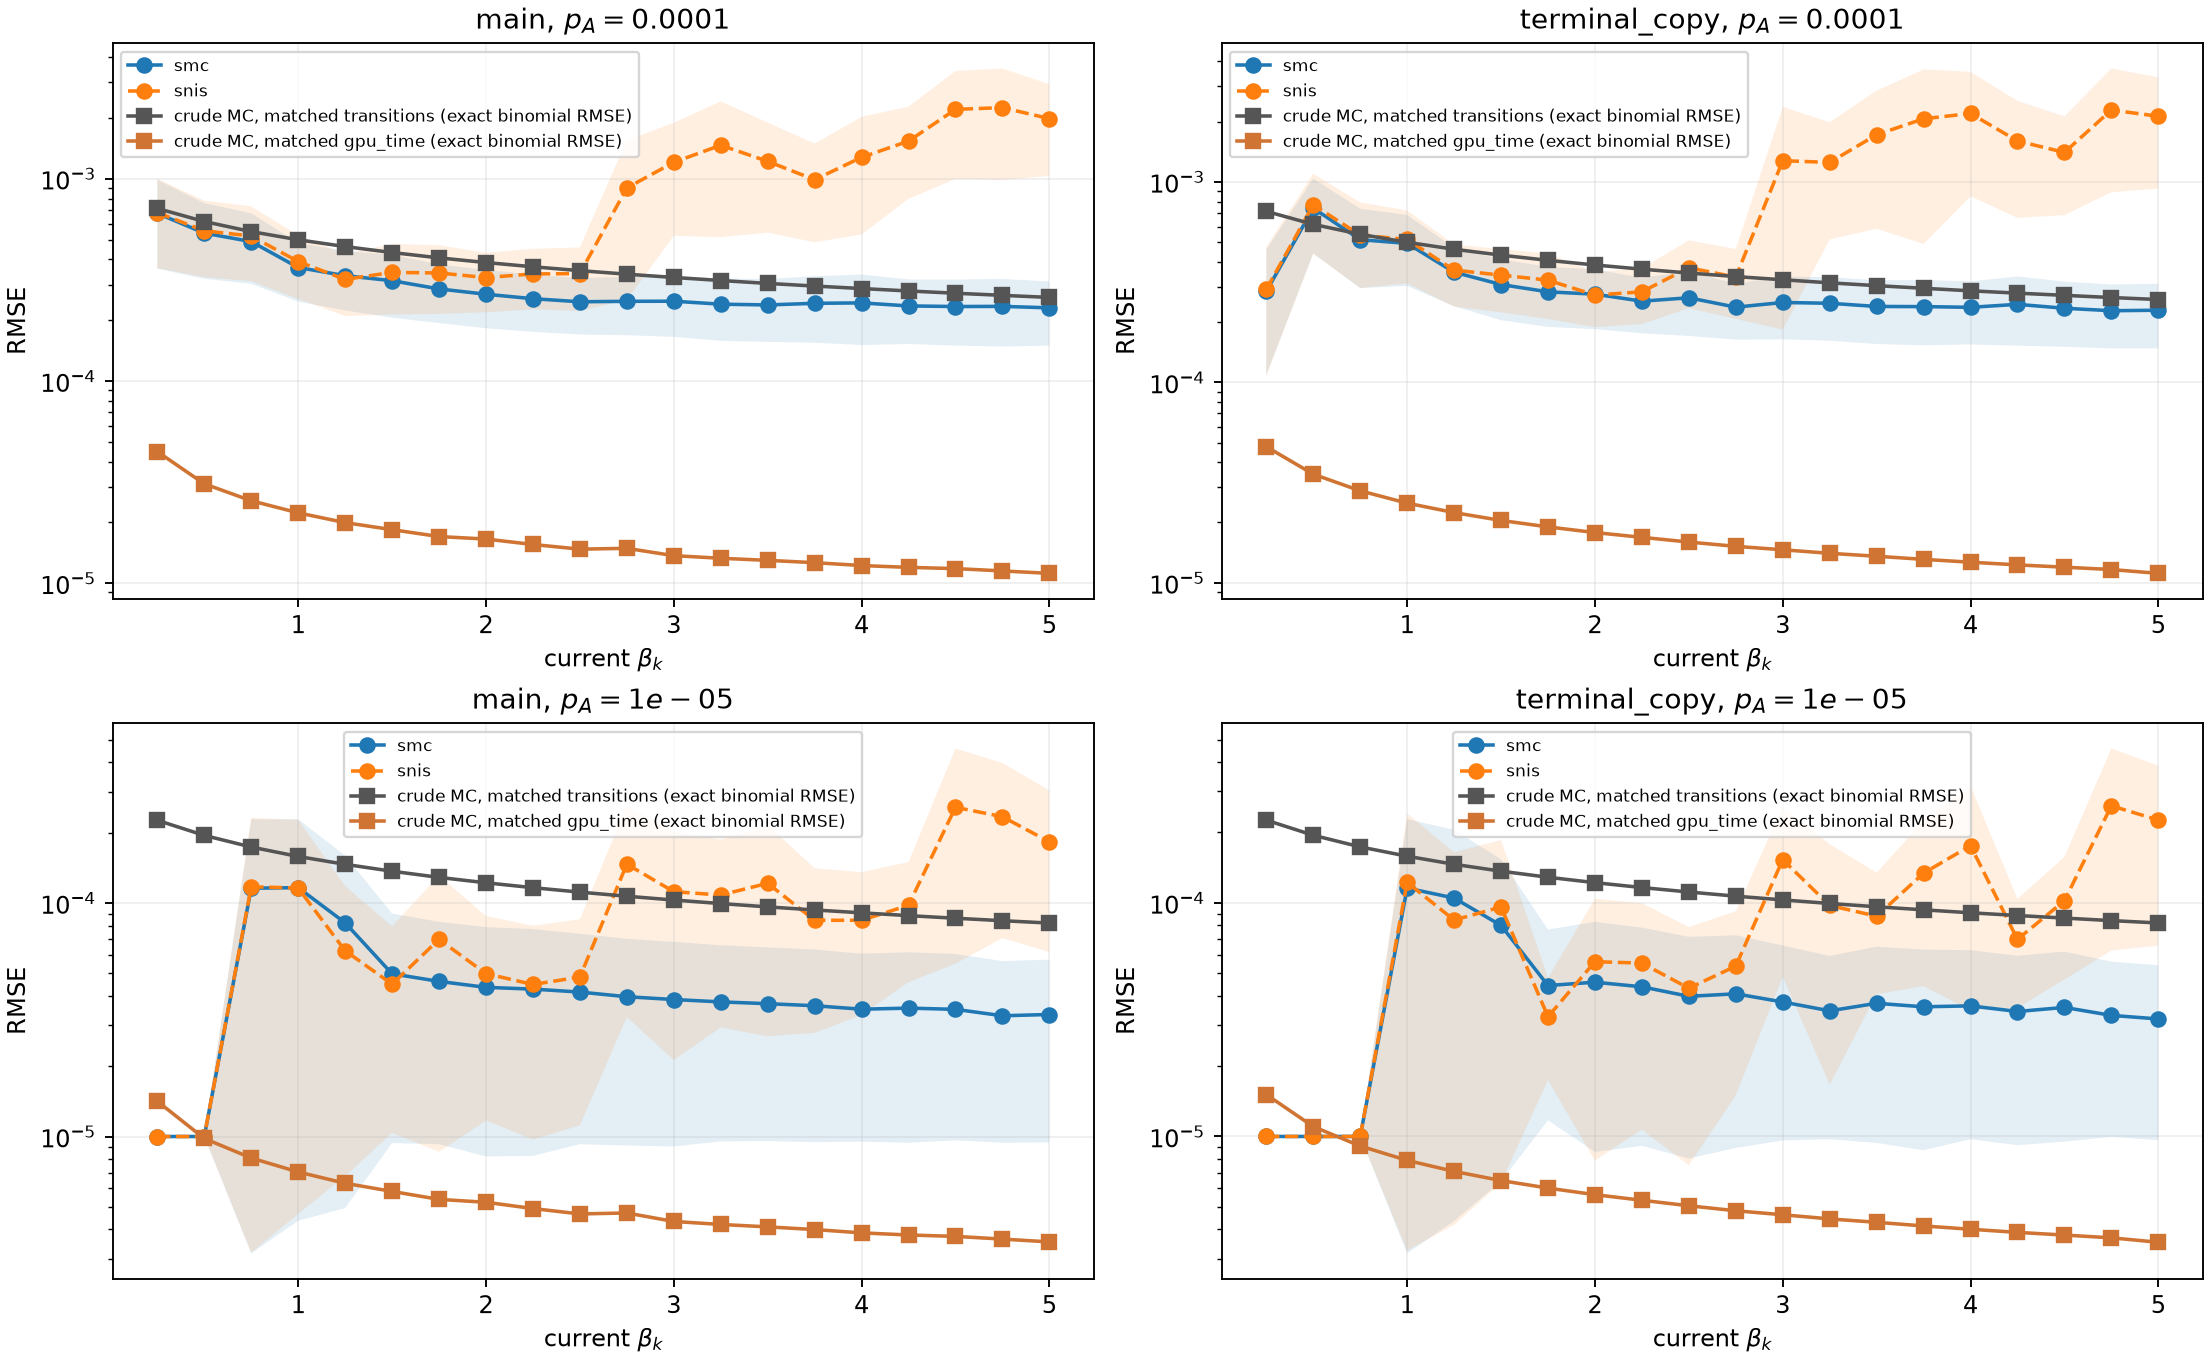

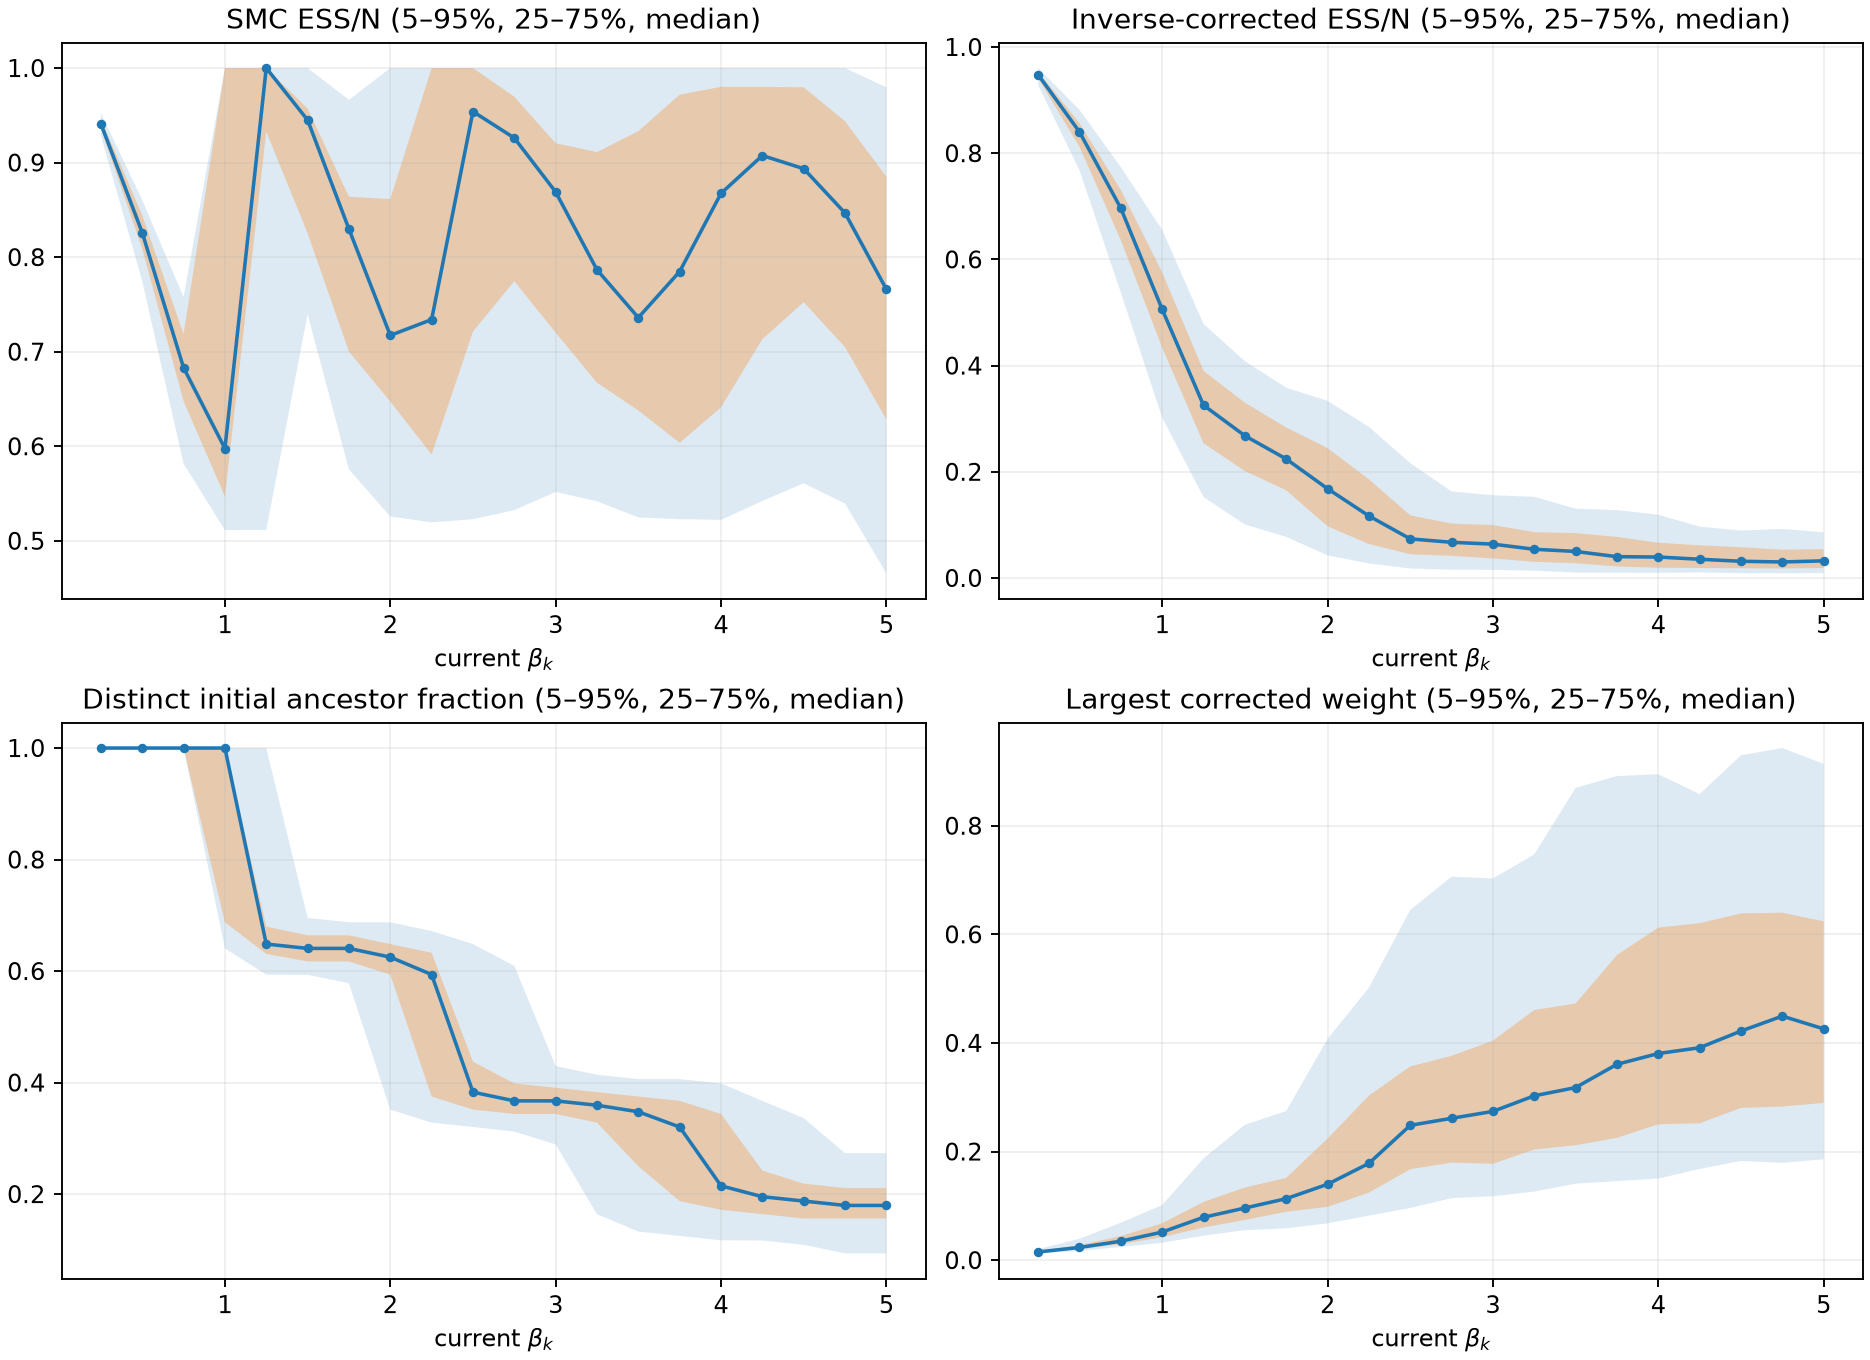

In [6]:
summary, crude_summary, diagnostics, budgets = replicated_experiment(checks)
print('Per-level SMC summary:')
display(summary)
print('Per-level crude MC summary:')
display(crude_summary)
print('Transition and GPU-time budgets:')
display(budgets)
display(Image(filename=str(OUT/'rmse_by_level.png')))
display(Image(filename=str(OUT/'diagnostics_by_level.png')))

In [7]:
print('Main-run final and selected intermediate levels:')
display(summary[(summary.population=='main') & summary.level.isin([1,5,10,15,20])][['p_A','level','beta','estimator','bias','variance','rmse','rmse_se','zero_fraction','median_event_particles','median_smc_ess_fraction','median_reverse_ess_fraction','median_root_fraction','median_main_cumulative_ms','median_main_transitions']])
print('Theoretical truth:', dict(zip(P_EVENTS,THRESHOLDS)))
print('Exact binomial crude MC benchmarks and empirical estimates are both in crude_summary.csv.')
print('No estimates from different beta levels were averaged.')

Main-run final and selected intermediate levels:


,p_A,level,beta,estimator,bias,variance,rmse,rmse_se,zero_fraction,median_event_particles,median_smc_ess_fraction,median_reverse_ess_fraction,median_root_fraction,median_main_cumulative_ms,median_main_transitions
0,0.00001,1,0.25,smc,-1.000000e-05,0.000000e+00,0.000010,7.236441e-23,1.000000,0.0,0.941040,0.947818,1.000000,3.98120,3133.0
1,0.00001,1,0.25,snis,-1.000000e-05,0.000000e+00,0.000010,7.236441e-23,1.000000,0.0,0.941040,0.947818,1.000000,3.98120,3133.0
8,0.00001,5,1.25,smc,-4.355645e-06,6.761239e-09,0.000082,3.942353e-05,0.990625,0.0,1.000000,0.325375,0.648438,19.10335,7478.0
9,0.00001,5,1.25,snis,-5.382347e-06,3.881213e-09,0.000062,2.840381e-05,0.990625,0.0,1.000000,0.325375,0.648438,19.10335,7478.0
18,0.00001,10,2.50,smc,-5.372104e-06,1.701588e-09,0.000042,1.646046e-05,0.918750,0.0,0.954005,0.073694,0.382812,37.34740,12920.0
19,0.00001,10,2.50,snis,-4.298878e-06,2.307578e-09,0.000048,1.887293e-05,0.918750,0.0,0.954005,0.073694,0.382812,37.34740,12920.0
28,0.00001,15,3.75,smc,-5.255530e-06,1.294342e-09,0.000036,1.369935e-05,0.759375,0.0,0.784787,0.040159,0.320312,55.48110,18376.0
29,0.00001,15,3.75,snis,2.739631e-06,7.119047e-09,0.000084,2.882708e-05,0.759375,0.0,0.784787,0.040159,0.320312,55.48110,18376.0
38,0.00001,20,5.00,smc,-5.339109e-06,1.083427e-09,0.000033,1.217329e-05,0.571875,0.0,0.765991,0.032295,0.179688,73.92575,23795.5
39,0.00001,20,5.00,snis,1.684073e-05,3.316669e-08,0.000183,6.169823e-05,0.571875,0.0,0.765991,0.032295,0.179688,73.92575,23795.5


Theoretical truth: {0.0001: 3.7190164854556804, 1e-05: 4.264890793922825}
Exact binomial crude MC benchmarks and empirical estimates are both in crude_summary.csv.
No estimates from different beta levels were averaged.


## Lettura dei risultati

Nel grafico delle stime della singola run, gli zeri sono visibili grazie alla scala simmetrica logaritmica. La copia terminale e la popolazione principale condividono la storia fino alla pesatura del livello; poi applicano mutazioni indipendenti, e la copia salta il resampling che una run terminata lì non avrebbe. La differenza a un livello non va interpretata come effetto causale isolato del resampling, perché cambia anche la mutazione stocastica.

Confrontare il RMSE a ogni $eta_k$ con l'RMSE crude allo stesso **costo cumulativo**. Il budget in transizioni usa il numero di transizioni gaussiane effettivamente impiegate nel suffisso, mentre il benchmark GPU usa il tempo misurato dell'intera stima. Il codice CUDA disegna per praticità un buffer di $T$ normali a ogni proposta: il numero di variabili generate è quindi registrato separatamente dalle transizioni usate. Un ESS terminale alto può seguire un reset dei pesi e coesistere con pochi antenati; un ESS corretto alto non assicura che l'evento raro compaia nella popolazione. Gli intervalli RMSE delle run SMC riflettono l'incertezza Monte Carlo fra run complete, senza usare la CLT della versione senza resampling.